K = 1 Accuracy = 0.9666666666666667
K = 2 Accuracy = 0.9333333333333333
K = 3 Accuracy = 0.9333333333333333
K = 4 Accuracy = 0.9333333333333333
K = 5 Accuracy = 0.9333333333333333
K = 6 Accuracy = 0.9333333333333333
K = 7 Accuracy = 0.9666666666666667
K = 8 Accuracy = 0.9333333333333333
K = 9 Accuracy = 0.9666666666666667
K = 10 Accuracy = 0.9666666666666667
K = 11 Accuracy = 0.9666666666666667
K = 12 Accuracy = 0.9666666666666667
K = 13 Accuracy = 0.9666666666666667
K = 14 Accuracy = 0.9333333333333333
K = 15 Accuracy = 0.9666666666666667
K = 16 Accuracy = 0.9666666666666667
K = 17 Accuracy = 0.9666666666666667
K = 18 Accuracy = 0.9666666666666667
K = 19 Accuracy = 0.9666666666666667
K = 20 Accuracy = 0.9666666666666667

Best K: 1
Best Accuracy: 0.9666666666666667


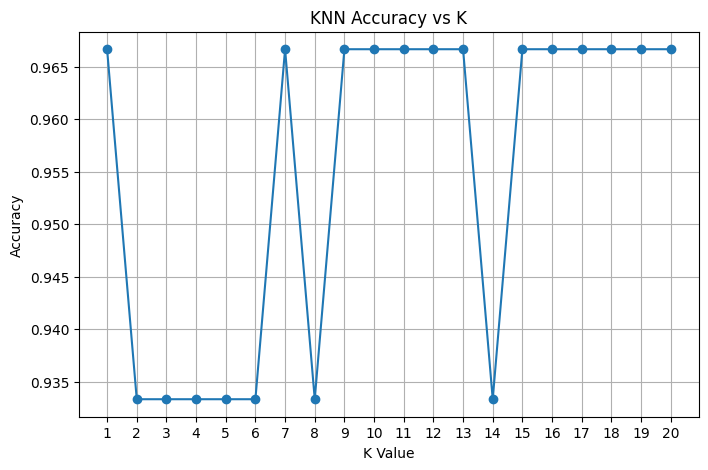


Final Accuracy: 0.9666666666666667

Confusion Matrix:
[[10  0  0]
 [ 0 10  0]
 [ 0  1  9]]


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix

# Load dataset
data = pd.read_csv("Iris.csv")

# Remove unnecessary ID column
data = data.drop("Id", axis=1)

# Separate input and output
X = data.drop("Species", axis=1)
y = data["Species"]

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Feature scaling
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Store K values and accuracies
k_values = []
accuracy_values = []

# Test K from 1 to 20
for k in range(1, 21):

    model = KNeighborsClassifier(
        n_neighbors=k
    )

    model.fit(X_train_scaled, y_train)

    prediction = model.predict(X_test_scaled)

    accuracy = accuracy_score(
        y_test,
        prediction
    )

    k_values.append(k)
    accuracy_values.append(accuracy)

    print("K =", k, "Accuracy =", accuracy)

# Find best K
best_index = np.argmax(accuracy_values)
best_k = k_values[best_index]
best_accuracy = accuracy_values[best_index]

print("\nBest K:", best_k)
print("Best Accuracy:", best_accuracy)

# Plot accuracy vs K
plt.figure(figsize=(8, 5))

plt.plot(
    k_values,
    accuracy_values,
    marker="o"
)

plt.xlabel("K Value")
plt.ylabel("Accuracy")
plt.title("KNN Accuracy vs K")
plt.xticks(k_values)
plt.grid(True)
plt.show()

# Train final model
final_model = KNeighborsClassifier(
    n_neighbors=best_k
)

final_model.fit(
    X_train_scaled,
    y_train
)

# Final prediction
final_prediction = final_model.predict(
    X_test_scaled
)

# Final accuracy
final_accuracy = accuracy_score(
    y_test,
    final_prediction
)

print("\nFinal Accuracy:", final_accuracy)

# Confusion matrix
matrix = confusion_matrix(
    y_test,
    final_prediction
)

print("\nConfusion Matrix:")
print(matrix)